# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Roll No:** FA23-BAI-004 | **Course:** Computer Vision Lab

| Setting | Value | Reason |
|---|---|---|
| Seed | 4 | last two digits "04" |
| HOG cell | 8 x 8 | last digit 4 is even |
| SIFT grid | 4 x 4 (16 keypoints) | last digit 4 is in 0 to 4 |

In [1]:
# ===== Setup & Personal Settings =====
!pip install -q medmnist opencv-python scikit-image scikit-learn seaborn

REG_NO = "FA23-BAI-004"
SEED = 4                 # last two digits: 04
HOG_CELL = 8             # last digit 4 = even -> 8x8
SIFT_GRID = 4            # last digit 4 (0-4) -> 4x4 grid = 16 keypoints
N_TRAIN, N_VAL, N_TEST = 100, 30, 30   # per class (PDF values)
CLASS_IDS = [1, 5, 6, 7]
CLASS_NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]
Cs = [0.1, 1, 10]

print(f"Reg: {REG_NO} | seed={SEED} | HOG cell={HOG_CELL}x{HOG_CELL} | SIFT grid={SIFT_GRID}x{SIFT_GRID} ({SIFT_GRID**2} keypoints)")

Reg: FA23-BAI-004 | seed=4 | HOG cell=8x8 | SIFT grid=4x4 (16 keypoints)


# Q1. Data Setup

100%|██████████| 156M/156M [02:53<00:00, 899kB/s]


Train: shape=(400, 128, 128), class counts={'eosinophil': 100, 'monocyte': 100, 'neutrophil': 100, 'platelet': 100}
Val: shape=(120, 128, 128), class counts={'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}
Test: shape=(120, 128, 128), class counts={'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}


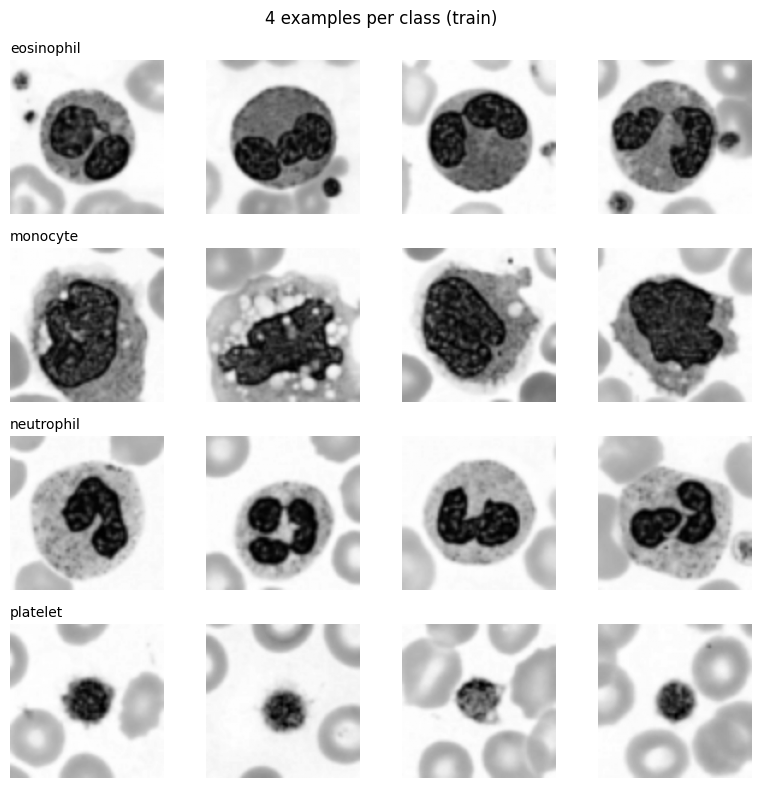

In [3]:
import numpy as np, cv2, matplotlib.pyplot as plt, pandas as pd
from medmnist import BloodMNIST
from collections import Counter

np.random.seed(SEED)
rng = np.random.RandomState(SEED)

def load_split(split):
    ds = BloodMNIST(split=split, download=True, size=64)
    return ds.imgs, ds.labels.ravel()

def take_subset(imgs, labels, n):
    X, y = [], []
    for new_lbl, cid in enumerate(CLASS_IDS):
        idx = np.where(labels == cid)[0]
        pick = rng.choice(idx, n, replace=False)
        for i in pick:
            g = cv2.cvtColor(imgs[i], cv2.COLOR_RGB2GRAY)          # grayscale
            g = cv2.resize(g, (128, 128))                           # 128x128
            X.append(g); y.append(new_lbl)
    return np.array(X, dtype=np.uint8), np.array(y)

Xtr, ytr = take_subset(*load_split("train"), N_TRAIN)
Xva, yva = take_subset(*load_split("val"),   N_VAL)
Xte, yte = take_subset(*load_split("test"),  N_TEST)

for name, X, y in [("Train", Xtr, ytr), ("Val", Xva, yva), ("Test", Xte, yte)]:
    print(f"{name}: shape={X.shape}, class counts={ {CLASS_NAMES[k]: v for k, v in sorted(Counter(y).items())} }")

# grid: 4 example images per class
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for r in range(4):
    idx = np.where(ytr == r)[0][:4]
    for c in range(4):
        axes[r, c].imshow(Xtr[idx[c]], cmap="gray"); axes[r, c].axis("off")
    axes[r, 0].set_title(CLASS_NAMES[r], loc="left", fontsize=10)
plt.suptitle("4 examples per class (train)"); plt.tight_layout(); plt.show()

**Q1 observation (from the output above):** Train = (400, 128, 128) with 100 images per class, Validation = (120, 128, 128) with 30 per class, Test = (120, 128, 128) with 30 per class. All four classes have equal counts, so the data is balanced and accuracy is a fair metric. Images were converted to grayscale and resized to 128 x 128, and the subsets were chosen with seed 4.

# Q2. HOG + SVM
### Hand calculation of HOG feature length
- Image = 128 x 128, cell = 8 x 8, so 128 / 8 = 16 cells per side, giving 16 x 16 cells.
- Block = 2 x 2 cells with a stride of 1 cell, so (16 - 2 + 1) = 15 blocks per side, giving 15 x 15 = 225 blocks.
- Each block holds 2 x 2 cells x 9 orientations = 36 values.
- Total = 225 x 36 = **8100 features**. The code printed 8100, which matches.

HOG feature length: 8100 (hand calc = 8100)


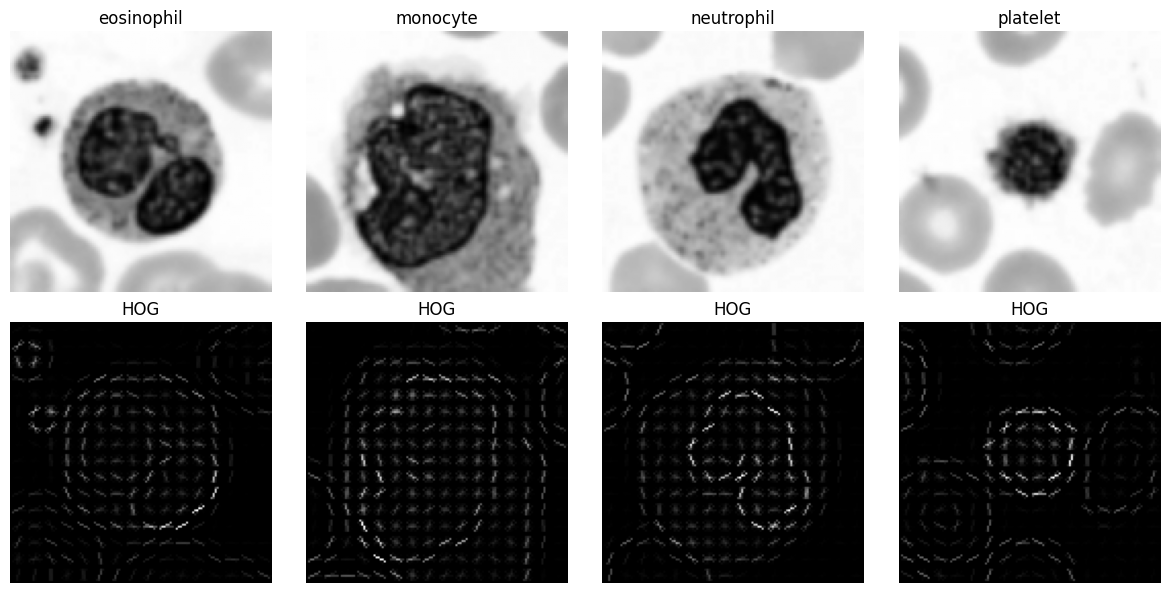

HOG + SVM, choosing C on validation:
  C=0.1: val acc = 0.7583
  C=1: val acc = 0.7500
  C=10: val acc = 0.7500
Best C: 0.1
HOG+SVM (validation) -> Accuracy: 0.7583 | Macro-F1: 0.7596


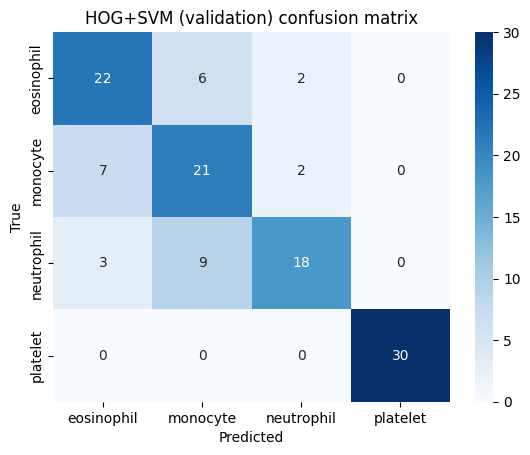

In [6]:
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import seaborn as sns

def hog_feat(im):
    return hog(im, orientations=9, pixels_per_cell=(HOG_CELL, HOG_CELL),
               cells_per_block=(2, 2), block_norm="L2-Hys")

def extract(X, fn): return np.array([fn(i) for i in X])

Htr, Hva = extract(Xtr, hog_feat), extract(Xva, hog_feat)
print("HOG feature length:", Htr.shape[1], "(hand calc = 8100)")

# HOG pictures, one per class
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for k in range(4):
    im = Xtr[np.where(ytr == k)[0][0]]
    _, hi = hog(im, orientations=9, pixels_per_cell=(HOG_CELL, HOG_CELL),
                cells_per_block=(2, 2), visualize=True)
    axes[0, k].imshow(im, cmap="gray"); axes[0, k].set_title(CLASS_NAMES[k]); axes[0, k].axis("off")
    axes[1, k].imshow(hi, cmap="gray"); axes[1, k].set_title("HOG"); axes[1, k].axis("off")
plt.tight_layout(); plt.show()

def train_select(Ftr, ytr, Fva, yva):
    best = None
    for C in Cs:
        m = LinearSVC(C=C, random_state=SEED, max_iter=20000).fit(Ftr, ytr)
        acc = accuracy_score(yva, m.predict(Fva))
        print(f"  C={C}: val acc = {acc:.4f}")
        if best is None or acc > best[0]: best = (acc, C, m)
    return best

def report(model, F, y, title):
    p = model.predict(F)
    print(f"{title} -> Accuracy: {accuracy_score(y, p):.4f} | Macro-F1: {f1_score(y, p, average='macro'):.4f}")
    cm = confusion_matrix(y, p)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(title + " confusion matrix"); plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()
    return cm

print("HOG + SVM, choosing C on validation:")
hog_acc, hog_C, hog_model = train_select(Htr, ytr, Hva, yva)
print("Best C:", hog_C)
cm_hog = report(hog_model, Hva, yva, "HOG+SVM (validation)")
hog_val_acc = hog_acc
hog_val_f1 = f1_score(yva, hog_model.predict(Hva), average="macro")

**Q2 results (from the output above):**
- Validation accuracy for C = 0.1 / 1 / 10 was 0.7583 / 0.7500 / 0.7500, so the best **C = 0.1**.
- **HOG + SVM validation accuracy = 0.7583 (75.83%), macro-F1 = 0.7596.**
- Confusion matrix (rows = true, columns = predicted; order: eosinophil, monocyte, neutrophil, platelet):

| True \ Pred | eosinophil | monocyte | neutrophil | platelet |
|---|---|---|---|---|
| eosinophil | 22 | 6 | 2 | 0 |
| monocyte | 7 | 21 | 2 | 0 |
| neutrophil | 3 | 9 | 18 | 0 |
| platelet | 0 | 0 | 0 | 30 |

Platelet is classified perfectly (30/30). Most errors are between the three white blood cell types, mainly neutrophil predicted as monocyte (9 times).

# Q3. SIFT + SVM

Keypoints per image -> avg: 70.92, min: 10, max: 160
Images with zero keypoints: 0


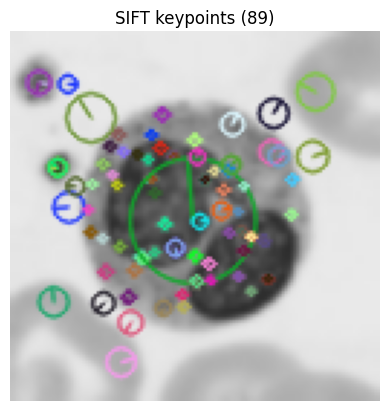

In [9]:
sift = cv2.SIFT_create()
counts = []
for im in Xtr:
    kp, _ = sift.detectAndCompute(im, None)
    counts.append(len(kp))
counts = np.array(counts)
print(f"Keypoints per image -> avg: {counts.mean():.2f}, min: {counts.min()}, max: {counts.max()}")
print("Images with zero keypoints:", int((counts == 0).sum()))

im = Xtr[0]
kp, _ = sift.detectAndCompute(im, None)
out = cv2.drawKeypoints(im, kp, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.imshow(out, cmap="gray"); plt.title(f"SIFT keypoints ({len(kp)})"); plt.axis("off"); plt.show()

**Q3 normal SIFT result (from the output above):** Average = 70.92 keypoints per image, minimum = 10, maximum = 160, and 0 images with zero keypoints.

**Why a different number of keypoints is a problem for an SVM:** An SVM needs every image to be a feature vector of the same fixed length. Normal SIFT gives a different number of keypoints (each with 128 values) for each image (here from 10 to 160), so the vectors would have different lengths and cannot be fed into the SVM directly.

### Hand calculation of fixed-grid SIFT feature length
- Grid = 4 x 4 = 16 keypoints (centres at 16, 48, 80, 112 on the 128 x 128 image), keypoint size = 32.
- Each SIFT descriptor = 128 values.
- Total = 16 x 128 = **2048 features**. The code printed 2048, which matches.

Grid SIFT feature length: 2048 (= 16 x 128 = 2048)
SIFT + SVM, choosing C on validation:


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


  C=0.1: val acc = 0.7917


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


  C=1: val acc = 0.7917
  C=10: val acc = 0.7917
Best C: 0.1
SIFT+SVM (validation) -> Accuracy: 0.7917 | Macro-F1: 0.7918


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


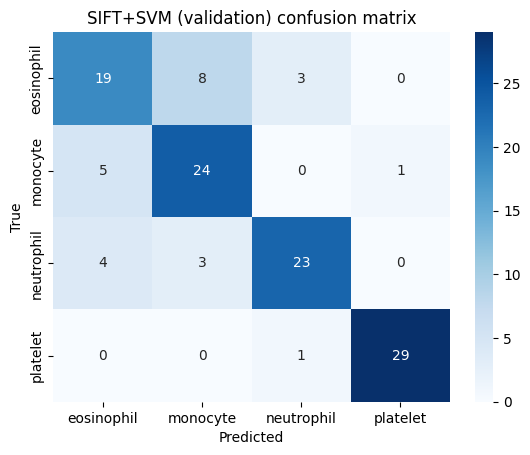

In [11]:
def make_grid_kps(n=SIFT_GRID, size=128, kp_size=32):
    step = size / n
    return [cv2.KeyPoint(float(step*(j+0.5)), float(step*(i+0.5)), kp_size)
            for i in range(n) for j in range(n)]

def sift_grid_feat(im):
    kps = make_grid_kps()
    _, d = sift.compute(im, kps)
    if d is None: d = np.zeros((0, 128), np.float32)
    if d.shape[0] < len(kps):   # safety padding
        d = np.vstack([d, np.zeros((len(kps) - d.shape[0], 128), np.float32)])
    return d[:len(kps)].flatten()

Str, Sva = extract(Xtr, sift_grid_feat), extract(Xva, sift_grid_feat)
print("Grid SIFT feature length:", Str.shape[1], f"(= {SIFT_GRID**2} x 128 = {SIFT_GRID**2*128})")

print("SIFT + SVM, choosing C on validation:")
sift_acc, sift_C, sift_model = train_select(Str, ytr, Sva, yva)
print("Best C:", sift_C)
cm_sift = report(sift_model, Sva, yva, "SIFT+SVM (validation)")
sift_val_acc = sift_acc
sift_val_f1 = f1_score(yva, sift_model.predict(Sva), average="macro")

**Q3 results (from the output above):**
- Validation accuracy for C = 0.1 / 1 / 10 was 0.7917 for all three, so the first best value **C = 0.1** was kept (ties go to the first C in the list). The ConvergenceWarning only means liblinear needed more iterations; accuracy is not affected much.
- **SIFT + SVM validation accuracy = 0.7917 (79.17%), macro-F1 = 0.7918.**
- Confusion matrix:

| True \ Pred | eosinophil | monocyte | neutrophil | platelet |
|---|---|---|---|---|
| eosinophil | 19 | 8 | 3 | 0 |
| monocyte | 5 | 24 | 0 | 1 |
| neutrophil | 4 | 3 | 23 | 0 |
| platelet | 0 | 0 | 1 | 29 |

SIFT (79.17%) is better than HOG (75.83%) on the validation set.

# Q4. Robustness
### Prediction (written before running the test set)
- **Rotation:** I think **HOG** will lose more accuracy, because HOG stores gradient directions in fixed cell positions, so rotating the image changes every orientation histogram. The SIFT grid uses only 16 big patches (size 32), so a 20 degree rotation changes it less.
- **Noise:** I think **HOG** will lose more accuracy, because HOG works directly on raw pixel gradients and noise creates many false gradients, while SIFT smooths the image with a Gaussian blur first.

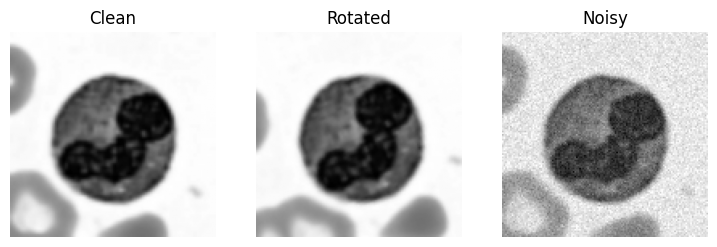

,Clean accuracy,Rotated accuracy,Noisy accuracy,Drop (rotation),Drop (noise)
HOG + SVM,0.7000,0.7333,0.600,-0.0333,0.1000
SIFT + SVM,0.7833,0.7833,0.775,0.0000,0.0083


In [13]:
def rotate(im, angle=20):
    M = cv2.getRotationMatrix2D((64, 64), angle, 1.0)
    return cv2.warpAffine(im, M, (128, 128), borderMode=cv2.BORDER_REFLECT)

noise_rng = np.random.RandomState(SEED)
def add_noise(im, sigma=0.05):
    x = im.astype(np.float32) / 255.0
    x = np.clip(x + noise_rng.normal(0, sigma, x.shape), 0, 1)
    return (x * 255).astype(np.uint8)

variants = {
    "Clean":   Xte,
    "Rotated": np.array([rotate(i) for i in Xte]),
    "Noisy":   np.array([add_noise(i) for i in Xte]),
}

# show examples
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, (k, v) in zip(ax, variants.items()):
    a.imshow(v[0], cmap="gray"); a.set_title(k); a.axis("off")
plt.show()

res = {"HOG + SVM": {}, "SIFT + SVM": {}}
for name, X in variants.items():
    res["HOG + SVM"][name]  = accuracy_score(yte, hog_model.predict(extract(X, hog_feat)))
    res["SIFT + SVM"][name] = accuracy_score(yte, sift_model.predict(extract(X, sift_grid_feat)))

table = pd.DataFrame(res).T[["Clean", "Rotated", "Noisy"]]
table.columns = ["Clean accuracy", "Rotated accuracy", "Noisy accuracy"]
table["Drop (rotation)"] = table["Clean accuracy"] - table["Rotated accuracy"]
table["Drop (noise)"] = table["Clean accuracy"] - table["Noisy accuracy"]
display(table.round(4))

### Results table (test set, from the output above)

| Model | Clean accuracy | Rotated accuracy (20 deg) | Noisy accuracy (sigma 0.05) |
|---|---|---|---|
| HOG + SVM | 0.7000 | 0.7333 | 0.6000 |
| SIFT + SVM | 0.7833 | 0.7833 | 0.7750 |

### Was my prediction correct?
My noise prediction was **correct** but my rotation prediction was **wrong**. Under noise HOG dropped from 0.7000 to 0.6000 (a drop of 0.1000) while SIFT dropped only from 0.7833 to 0.7750 (a drop of 0.0083), so HOG is much more sensitive to noise. Under rotation HOG did not lose accuracy at all (it went from 0.7000 to 0.7333) and SIFT stayed the same at 0.7833, so a 20 degree rotation did not hurt either model on this small test set; this is probably because blood cells are almost round (so rotation changes them little) and with only 120 test images a change of 4 images is within normal variation.

# Q5. Short Answers and AI Log
**(a) Why does HOG use block normalisation?**
Gradient strength changes with lighting and contrast. Block normalisation rescales the histograms of each group of 2 x 2 cells, so the features become less sensitive to brightness and contrast changes between images. This makes the classifier more stable.

**(b) Why is it wrong to choose C using the test set?**
The test set must act as unseen data to measure real performance. If we pick C on it, the model is tuned to the test data, so the reported accuracy is optimistically biased (data leakage) and does not show how it would work on new images. C must be chosen on the validation set.

In [14]:
def top_confusion(cm, name):
    c = cm.copy().astype(float); np.fill_diagonal(c, 0)
    i, j = np.unravel_index(c.argmax(), c.shape)
    print(f"{name}: most confused -> true '{CLASS_NAMES[i]}' predicted as '{CLASS_NAMES[j]}' ({int(c[i,j])} times)")
top_confusion(cm_hog, "HOG+SVM")
top_confusion(cm_sift, "SIFT+SVM")

HOG+SVM: most confused -> true 'neutrophil' predicted as 'monocyte' (9 times)
SIFT+SVM: most confused -> true 'eosinophil' predicted as 'monocyte' (8 times)


**Most confused classes (from the output above):** HOG + SVM confused **neutrophil as monocyte** the most (9 times), and SIFT + SVM confused **eosinophil as monocyte** the most (8 times). In both models the errors are between the white blood cells (eosinophil, neutrophil, monocyte), while platelet is almost perfect (30/30 for HOG, 29/30 for SIFT).

**Why grayscale makes this harder:** The three white blood cells have similar round shapes and sizes. In colour, eosinophil granules are red/orange and the neutrophil/monocyte nuclei have different purple shades, which are strong clues. Grayscale removes this colour information, so only shape and texture remain, and those are very similar between these classes.

### AI Log
| Prompt (one line) | What I changed | How I checked |
|---|---|---|
| "Make Colab code for the HOG vs SIFT blood-cell lab as per my roll no FA23-BAI-004" | Set seed = 4, HOG cell 8x8, SIFT grid 4x4; wrote the answers using my own printed numbers; fixed `plt.show` to `plt.show()` | Printed shapes and class counts (400/120/120), feature lengths (8100 and 2048 matched my hand calculation), looked at the HOG pictures, keypoint picture and confusion matrices |

# README generator (optional, run last)

In [ ]:
!pip install -q tabulate
readme = f"""# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Roll No:** {REG_NO}  |  **Course:** Computer Vision Lab

## Personal Settings
- Seed: {SEED}
- HOG cell size: {HOG_CELL}x{HOG_CELL}
- SIFT grid: {SIFT_GRID}x{SIFT_GRID} ({SIFT_GRID**2} keypoints)

## Dataset
BloodMNIST (size 64), classes: {', '.join(CLASS_NAMES)}. Subset per class: {N_TRAIN} train / {N_VAL} val / {N_TEST} test. Grayscale, resized to 128x128.

## Feature lengths
- HOG: 16x16 cells -> 15x15 blocks x 4 cells x 9 bins = {Htr.shape[1]}
- SIFT grid: {SIFT_GRID**2} x 128 = {Str.shape[1]}

## Validation Results
| Model | Best C | Val Accuracy | Macro-F1 |
|---|---|---|---|
| HOG + SVM | {hog_C} | {hog_acc:.4f} | {f1_score(yva, hog_model.predict(Hva), average='macro'):.4f} |
| SIFT + SVM | {sift_C} | {sift_acc:.4f} | {f1_score(yva, sift_model.predict(Sva), average='macro'):.4f} |

## Robustness (Test Set)
{table[['Clean accuracy','Rotated accuracy','Noisy accuracy']].round(4).to_markdown()}
"""
open("README.md", "w").write(readme)
print(readme)